# Binance daily SVM grid search: step-by-step walkthrough

This notebook explains and executes the approved BTCUSDT development grid search one stage at a time. It reuses the repository implementation in `src/tcc_crypto/daily_svm_grid_search.py`; the notebook does not create an alternative modeling pipeline.

The walkthrough covers configuration, development-only data, target balance, asset eligibility, temporal folds, fold-local feature selection and scaling, conditional SVC candidates, model ranking, selected configurations, and persisted evidence.

## Methodological boundaries

- Feature dates in development run from 2019-07-01 through 2024-12-30.
- The 2024-12-31 candle is used only to construct the target for the 2024-12-30 feature row.
- Final-test feature rows beginning on 2025-01-01 are not retained, calculated, or used.
- Inputs at `t` map to the next day's same-candle return: `features(t) -> D0(t + 1)`.
- Searches are independent for each symbol, target, and 60-, 75-, or 90-day training window.
- Every inner split has a 60-observation validation block and a one-observation gap.
- Feature selection and `StandardScaler` are fitted only on each inner training fold.
- Mean validation F1 is the primary selection metric. The final test is outside this notebook.

In [1]:
from __future__ import annotations

import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


def find_repository_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / 'pyproject.toml').exists() and (candidate / 'src').exists():
            return candidate
    raise FileNotFoundError('Could not locate the repository root.')


REPOSITORY_ROOT = find_repository_root()
os.chdir(REPOSITORY_ROOT)
SOURCE_DIRECTORY = REPOSITORY_ROOT / 'src'
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))

from tcc_crypto.daily_feature_selection import DailyFeatureSelector
from tcc_crypto.daily_features import ACTIVE_FEATURES, load_daily_feature_config
from tcc_crypto.daily_svm_grid_search import (
    assess_symbol_eligibility,
    build_symbol_development_dataset,
    calculate_classification_metrics,
    expand_parameter_grid,
    load_daily_svm_grid_search_config,
    run_temporal_grid_search,
    temporal_splits,
    write_grid_search_outputs,
)

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 180)
print(f'Repository root: {REPOSITORY_ROOT}')

Repository root: /Users/marcelapsilverio/projetos/tcc_crypto


## 1. Load and validate the approved configuration

The JSON configuration is the source of executable experiment parameters. The loader rejects changes that conflict with the approved methodology, such as random shuffling, different dates, or a grid with the wrong number of candidates.

In [2]:
GRID_CONFIG_PATH = REPOSITORY_ROOT / 'configs/binance_daily_svm_grid_search.json'
grid_config = load_daily_svm_grid_search_config(GRID_CONFIG_PATH)
feature_config = load_daily_feature_config(REPOSITORY_ROOT / grid_config.feature_config)

configuration_overview = pd.Series(
    {
        'experiment_id': grid_config.experiment_id,
        'development_start_utc': grid_config.development_start_utc,
        'development_end_utc': grid_config.development_end_utc,
        'targets': grid_config.targets,
        'training_window_sizes': grid_config.training_window_sizes,
        'inner_splits': grid_config.n_splits,
        'validation_block_size': grid_config.test_size,
        'gap_observations': grid_config.gap,
        'minimum_complete_rows': grid_config.minimum_complete_rows,
        'candidate_count_per_search': grid_config.candidate_count,
        'primary_metric': grid_config.primary_metric,
        'explicitly_excluded_symbols': grid_config.excluded_symbols,
    },
    name='approved_value',
)
display(configuration_overview.to_frame())

,approved_value
experiment_id,binance_daily_svm_temporal_grid_search_v1
development_start_utc,2019-07-01 00:00:00+00:00
development_end_utc,2024-12-30 00:00:00+00:00
targets,"(target_2pct, target_3pct, target_4pct)"
training_window_sizes,"(60, 75, 90)"
inner_splits,3
validation_block_size,60
gap_observations,1
minimum_complete_rows,271
candidate_count_per_search,186


## 2. Expand the conditional hyperparameter grid

The grid is conditional: parameters appear only for kernels that use them. This produces 6 linear, 18 RBF, and 162 polynomial candidates, for 186 candidates per symbol-target-window search.

In [3]:
parameter_candidates = expand_parameter_grid(grid_config.parameter_grid)
parameter_table = pd.DataFrame(parameter_candidates)
parameter_table.insert(0, 'candidate_order', range(len(parameter_table)))

branch_counts = (
    parameter_table.groupby('kernel', sort=False)
    .size()
    .rename('candidate_count')
    .to_frame()
)
display(branch_counts)
display(parameter_table.head(10))
print(f'Total compatible candidates: {len(parameter_table)}')

Total compatible candidates: 186


,candidate_count
kernel,
linear,6
rbf,18
poly,162


,candidate_order,kernel,C,class_weight,gamma,degree,coef0
0,0,linear,0.1,None,NaN,NaN,NaN
1,1,linear,0.1,balanced,NaN,NaN,NaN
2,2,linear,1.0,None,NaN,NaN,NaN
3,3,linear,1.0,balanced,NaN,NaN,NaN
4,4,linear,10.0,None,NaN,NaN,NaN
5,5,linear,10.0,balanced,NaN,NaN,NaN
6,6,rbf,0.1,None,scale,NaN,NaN
7,7,rbf,0.1,balanced,scale,NaN,NaN
8,8,rbf,0.1,None,0.01,NaN,NaN
9,9,rbf,0.1,balanced,0.01,NaN,NaN


## 3. Build the BTCUSDT development dataset

This calls the same development-data builder used by the command-line runner. It applies the approved internal-gap treatment in derived data, calculates the 22 features, removes only leading indicator warm-up rows, and constructs the three next-day targets.

In [4]:
symbol = 'BTCUSDT'
development_source = build_symbol_development_dataset(grid_config, symbol)
development_dataset = development_source.dataset

dataset_overview = pd.Series(
    {
        'symbol': symbol,
        'raw_source': development_source.raw_path,
        'development_rows': len(development_dataset),
        'feature_count': len(ACTIVE_FEATURES),
        'first_feature_date_utc': development_dataset.index.min(),
        'last_feature_date_utc': development_dataset.index.max(),
        'latest_target_date_utc': development_dataset['target_date_utc'].max(),
        'feature_imputed_rows': int(development_dataset['feature_is_imputed'].sum()),
        'target_imputed_rows': int(development_dataset['target_is_imputed'].fillna(False).sum()),
        'missing_active_feature_cells': int(development_dataset.loc[:, ACTIVE_FEATURES].isna().sum().sum()),
    },
    name='development_dataset',
)
display(dataset_overview.to_frame())
display(development_dataset.head(5))

,development_dataset
symbol,BTCUSDT
raw_source,data/raw/binance/spot/1d/BTCUSDT/BTCUSDT_1d_20...
development_rows,2010
feature_count,22
first_feature_date_utc,2019-07-01 00:00:00+00:00
last_feature_date_utc,2024-12-30 00:00:00+00:00
latest_target_date_utc,2024-12-31 00:00:00+00:00
feature_imputed_rows,0
target_imputed_rows,0
missing_active_feature_cells,0


,symbol,feature_is_imputed,r1,r2,r3,r4,r5,r6,r7,r8,r9,r10,r11,r12,r13,r14,r15,momentum_10,rsi_14,parabolic_sar,atr_14,true_range,chaikin_ad,obv,target_date_utc,next_day_open,next_day_high,next_day_d0,target_is_imputed,target_2pct,target_3pct,target_4pct
feature_date_utc,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2019-07-01 00:00:00+00:00,BTCUSDT,False,-0.021340,-0.092259,-0.040946,0.090294,0.038690,-0.053568,-0.095032,-0.004220,0.022994,0.002775,0.096674,-0.078962,-0.100406,-0.078093,-0.031115,465.07,52.859527,7444.58,943.361958,1252.28,2.364909e+09,4.148481e+09,2019-07-02 00:00:00+00:00,10624.90,10938.75,0.029539,False,1,0,0
2019-07-02 00:00:00+00:00,BTCUSDT,False,0.020303,-0.021340,-0.092259,-0.040946,0.029111,0.007769,-0.084490,-0.125954,0.038690,0.022994,0.002775,-0.088295,-0.078962,-0.100406,-0.078093,113.35,54.309046,7444.58,962.532532,1211.75,3.314663e+09,5.276835e+09,2019-07-03 00:00:00+00:00,10844.98,11991.89,0.105755,False,1,1,1
2019-07-03 00:00:00+00:00,BTCUSDT,False,0.096388,0.020303,-0.021340,-0.092259,0.100528,0.121030,0.099688,0.007429,0.029111,0.038690,0.022994,-0.000363,-0.088295,-0.078962,-0.100406,1033.93,60.838063,7444.58,975.983780,1150.85,4.313471e+09,6.374640e+09,2019-07-04 00:00:00+00:00,11940.00,12000.00,0.005025,False,0,0,0
2019-07-04 00:00:00+00:00,BTCUSDT,False,-0.068843,0.096388,0.020303,-0.021340,0.005013,0.101204,0.121706,0.100364,0.100528,0.029111,0.038690,-0.077011,-0.000363,-0.088295,-0.078962,89.08,54.739367,7444.58,973.770653,945.00,3.686527e+09,5.598821e+09,2019-07-05 00:00:00+00:00,11145.67,11406.83,0.023432,False,1,0,0
2019-07-05 00:00:00+00:00,BTCUSDT,False,-0.015820,-0.068843,0.096388,0.020303,0.023161,-0.045682,0.050510,0.071012,0.005013,0.100528,0.029111,-0.031835,-0.077011,-0.000363,-0.088295,-850.13,53.468122,7444.58,947.814892,610.39,3.383771e+09,4.892967e+09,2019-07-06 00:00:00+00:00,10982.41,11665.00,0.062153,False,1,1,1


## 4. Inspect target balance

Higher return thresholds create fewer positive observations. Accuracy alone can therefore look acceptable even when a classifier rarely detects the positive class, which is why F1, precision, recall, ROC-AUC, and average precision are retained.

<ipython-input-5-962fa16e7c58>:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,negative,positive,positive_rate
target,,,
target_2pct,1179,831,0.413433
target_3pct,1474,536,0.266667
target_4pct,1663,347,0.172637


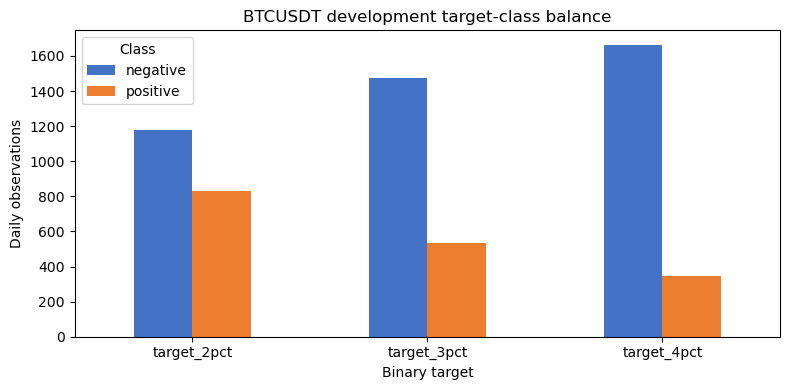

In [5]:
target_balance_rows = []
for target in grid_config.targets:
    labels = development_dataset[target].dropna().astype('int64')
    target_balance_rows.append(
        {
            'target': target,
            'negative': int((labels == 0).sum()),
            'positive': int((labels == 1).sum()),
            'positive_rate': float((labels == 1).mean()),
        }
    )
target_balance = pd.DataFrame(target_balance_rows).set_index('target')
display(target_balance)

ax = target_balance[['negative', 'positive']].plot.bar(
    figsize=(8, 4), color=['#4472C4', '#ED7D31']
)
ax.set_title('BTCUSDT development target-class balance')
ax.set_xlabel('Binary target')
ax.set_ylabel('Daily observations')
ax.legend(title='Class')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Evaluate search eligibility

Eligibility is checked separately for every target and training window. A search needs at least 271 complete labeled rows and both classes in every inner training fold. Exclusions and failures are recorded instead of being silently discarded.

In [6]:
eligibility = assess_symbol_eligibility(
    development_dataset,
    symbol=symbol,
    config=grid_config,
)
display(
    eligibility.loc[
        :,
        [
            'symbol',
            'target',
            'window_size',
            'status',
            'reason',
            'complete_labeled_rows',
            'negative_count',
            'positive_count',
        ],
    ]
)

,symbol,target,window_size,status,reason,complete_labeled_rows,negative_count,positive_count
0,BTCUSDT,target_2pct,60,eligible,,2010,1179,831
1,BTCUSDT,target_2pct,75,eligible,,2010,1179,831
2,BTCUSDT,target_2pct,90,eligible,,2010,1179,831
3,BTCUSDT,target_3pct,60,eligible,,2010,1474,536
4,BTCUSDT,target_3pct,75,eligible,,2010,1474,536
5,BTCUSDT,target_3pct,90,eligible,,2010,1474,536
6,BTCUSDT,target_4pct,60,eligible,,2010,1663,347
7,BTCUSDT,target_4pct,75,eligible,,2010,1663,347
8,BTCUSDT,target_4pct,90,eligible,,2010,1663,347


## 6. Visualize the temporal split boundaries

The example below uses the 90-day window. Each validation block contains 60 later observations. The one row between training and validation is excluded as the gap. No row is shuffled.

In [7]:
example_target = 'target_2pct'
example_window_size = 90
example_complete = development_dataset.loc[:, [*ACTIVE_FEATURES, example_target]].dropna()
example_splits = temporal_splits(len(example_complete), grid_config, example_window_size)

split_rows = []
for fold, (training_positions, validation_positions) in enumerate(example_splits):
    gap_start = training_positions[-1] + 1
    split_rows.append(
        {
            'fold': fold,
            'training_start_utc': example_complete.index[training_positions[0]],
            'training_end_utc': example_complete.index[training_positions[-1]],
            'training_rows': len(training_positions),
            'gap_date_utc': example_complete.index[gap_start],
            'validation_start_utc': example_complete.index[validation_positions[0]],
            'validation_end_utc': example_complete.index[validation_positions[-1]],
            'validation_rows': len(validation_positions),
        }
    )
split_boundaries = pd.DataFrame(split_rows)
display(split_boundaries)

,fold,training_start_utc,training_end_utc,training_rows,gap_date_utc,validation_start_utc,validation_end_utc,validation_rows
0,0,2024-04-04 00:00:00+00:00,2024-07-02 00:00:00+00:00,90,2024-07-03 00:00:00+00:00,2024-07-04 00:00:00+00:00,2024-09-01 00:00:00+00:00,60
1,1,2024-06-03 00:00:00+00:00,2024-08-31 00:00:00+00:00,90,2024-09-01 00:00:00+00:00,2024-09-02 00:00:00+00:00,2024-10-31 00:00:00+00:00,60
2,2,2024-08-02 00:00:00+00:00,2024-10-30 00:00:00+00:00,90,2024-10-31 00:00:00+00:00,2024-11-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,60


## 7. Inspect preprocessing inside one fold

The selector is fitted only on the 90 training rows. The validation rows are transformed with that fitted selector. Then `StandardScaler` is fitted only on the selected training matrix and applied unchanged to validation.

In [8]:
training_positions, validation_positions = example_splits[0]
feature_matrix = example_complete.loc[:, ACTIVE_FEATURES].astype('float64')
labels = example_complete[example_target].astype('int64')
training_features = feature_matrix.iloc[training_positions]
validation_features = feature_matrix.iloc[validation_positions]
training_labels = labels.iloc[training_positions]
validation_labels = labels.iloc[validation_positions]

selector = DailyFeatureSelector(
    variance_threshold=feature_config.feature_selection.variance_threshold,
    correlation_threshold=feature_config.feature_selection.correlation_threshold,
)
selected_training = selector.fit_transform(training_features)
selected_validation = selector.transform(validation_features)
scaler = StandardScaler()
scaled_training = scaler.fit_transform(selected_training)
scaled_validation = scaler.transform(selected_validation)

preprocessing_overview = pd.Series(
    {
        'input_feature_count': training_features.shape[1],
        'selected_feature_count': len(selector.selected_features_),
        'selected_features': ', '.join(selector.selected_features_),
        'training_rows_used_to_fit': len(training_features),
        'validation_rows_only_transformed': len(validation_features),
        'training_negative': int((training_labels == 0).sum()),
        'training_positive': int((training_labels == 1).sum()),
    },
    name='fold_0_preprocessing',
)
display(preprocessing_overview.to_frame())

scaled_training_frame = pd.DataFrame(
    scaled_training, columns=selected_training.columns, index=selected_training.index
)
display(
    pd.DataFrame(
        {
            'training_mean_after_scaling': scaled_training_frame.mean(),
            'training_std_after_scaling': scaled_training_frame.std(ddof=0),
        }
    )
)

,fold_0_preprocessing
input_feature_count,22
selected_feature_count,6
selected_features,"momentum_10, rsi_14, atr_14, true_range, chaik..."
training_rows_used_to_fit,90
validation_rows_only_transformed,60
training_negative,63
training_positive,27


,training_mean_after_scaling,training_std_after_scaling
momentum_10,4.687608e-17,1.0
rsi_14,-3.355341e-16,1.0
atr_14,2.664535e-16,1.0
true_range,-1.603655e-16,1.0
chaikin_ad,1.080124e-14,1.0
obv,-1.233581e-16,1.0


## 8. Compare one candidate from each kernel branch

This educational cell fits three candidates on the same preprocessed fold. The official search repeats this for every compatible candidate and every temporal fold. ROC-AUC and average precision use the continuous `decision_function` score, not the binary prediction.

In [9]:
example_candidate_orders = [0, 6, 24]
example_candidate_rows = []
for candidate_order in example_candidate_orders:
    parameters = parameter_candidates[candidate_order]
    estimator = SVC(**parameters)
    estimator.fit(scaled_training, training_labels)
    predictions = estimator.predict(scaled_validation)
    decision_scores = estimator.decision_function(scaled_validation)
    metrics = calculate_classification_metrics(
        validation_labels.to_numpy(), predictions, decision_scores
    )
    example_candidate_rows.append(
        {
            'candidate_order': candidate_order,
            **parameters,
            **metrics,
        }
    )
example_candidate_comparison = pd.DataFrame(example_candidate_rows)
display(example_candidate_comparison)

,candidate_order,kernel,C,class_weight,accuracy,precision,recall,f1,balanced_accuracy,roc_auc,average_precision,metric_diagnostic,gamma,degree,coef0
0,0,linear,0.1,None,0.566667,0.0,0.000000,0.000000,0.500000,0.598416,0.580851,,NaN,NaN,NaN
1,6,rbf,0.1,None,0.566667,0.0,0.000000,0.000000,0.500000,0.479638,0.484110,,scale,NaN,NaN
2,24,poly,0.1,None,0.583333,1.0,0.038462,0.074074,0.519231,0.416290,0.418009,,scale,2.0,0.0


## 9. Run the complete approved BTCUSDT grid search

This is the complete development search: 186 candidates × 3 folds × 3 targets × 3 training windows = 5,022 candidate-fold fits. It normally completes in under one minute on the development machine. It still does not execute the final test.

In [10]:
grid_result = run_temporal_grid_search(
    development_dataset,
    symbol=symbol,
    config=grid_config,
    selection_config=feature_config.feature_selection,
)

run_overview = pd.Series(
    {
        'eligible_searches': int((grid_result.eligibility['status'] == 'eligible').sum()),
        'candidate_fold_fits': len(grid_result.fold_results),
        'successful_fits': int((grid_result.fold_results['status'] == 'ok').sum()),
        'fit_errors': int((grid_result.fold_results['status'] != 'ok').sum()),
        'aggregate_candidate_rows': len(grid_result.candidate_results),
        'selected_configurations': len(grid_result.selected_configurations),
        'latest_validation_date_utc': grid_result.fold_results['validation_end_utc'].max(),
    },
    name='complete_grid_search',
)
display(run_overview.to_frame())

,complete_grid_search
eligible_searches,9
candidate_fold_fits,5022
successful_fits,5022
fit_errors,0
aggregate_candidate_rows,1674
selected_configurations,9
latest_validation_date_utc,2024-12-30 00:00:00+00:00


## 10. Inspect fold-level evidence

Each row below is one candidate evaluated on one fold. It records temporal boundaries, class counts, selected features, metrics, diagnostics, and fit duration.

In [11]:
fold_columns = [
    'target',
    'window_size',
    'candidate_order',
    'fold',
    'kernel',
    'C',
    'training_start_utc',
    'training_end_utc',
    'validation_start_utc',
    'validation_end_utc',
    'selected_feature_count',
    'accuracy',
    'precision',
    'recall',
    'f1',
    'roc_auc',
    'average_precision',
    'status',
]
display(grid_result.fold_results.loc[:, fold_columns].head(12))

,target,window_size,candidate_order,fold,kernel,C,training_start_utc,training_end_utc,validation_start_utc,validation_end_utc,selected_feature_count,accuracy,precision,recall,f1,roc_auc,average_precision,status
0,target_2pct,60,0,0,linear,0.1,2024-05-04 00:00:00+00:00,2024-07-02 00:00:00+00:00,2024-07-04 00:00:00+00:00,2024-09-01 00:00:00+00:00,4,0.566667,0.000000,0.000000,0.000000,0.697964,0.639417,ok
1,target_2pct,60,1,0,linear,0.1,2024-05-04 00:00:00+00:00,2024-07-02 00:00:00+00:00,2024-07-04 00:00:00+00:00,2024-09-01 00:00:00+00:00,4,0.583333,0.511111,0.884615,0.647887,0.721719,0.670802,ok
2,target_2pct,60,2,0,linear,1.0,2024-05-04 00:00:00+00:00,2024-07-02 00:00:00+00:00,2024-07-04 00:00:00+00:00,2024-09-01 00:00:00+00:00,4,0.566667,0.000000,0.000000,0.000000,0.634615,0.588143,ok
3,target_2pct,60,3,0,linear,1.0,2024-05-04 00:00:00+00:00,2024-07-02 00:00:00+00:00,2024-07-04 00:00:00+00:00,2024-09-01 00:00:00+00:00,4,0.550000,0.488372,0.807692,0.608696,0.722851,0.660112,ok
4,target_2pct,60,4,0,linear,10.0,2024-05-04 00:00:00+00:00,2024-07-02 00:00:00+00:00,2024-07-04 00:00:00+00:00,2024-09-01 00:00:00+00:00,4,0.566667,0.000000,0.000000,0.000000,0.589367,0.540293,ok
5,target_2pct,60,5,0,linear,10.0,2024-05-04 00:00:00+00:00,2024-07-02 00:00:00+00:00,2024-07-04 00:00:00+00:00,2024-09-01 00:00:00+00:00,4,0.550000,0.488372,0.807692,0.608696,0.722851,0.655848,ok
6,target_2pct,60,6,0,rbf,0.1,2024-05-04 00:00:00+00:00,2024-07-02 00:00:00+00:00,2024-07-04 00:00:00+00:00,2024-09-01 00:00:00+00:00,4,0.566667,0.000000,0.000000,0.000000,0.548643,0.554685,ok
7,target_2pct,60,7,0,rbf,0.1,2024-05-04 00:00:00+00:00,2024-07-02 00:00:00+00:00,2024-07-04 00:00:00+00:00,2024-09-01 00:00:00+00:00,4,0.450000,0.360000,0.346154,0.352941,0.460407,0.481833,ok
8,target_2pct,60,8,0,rbf,0.1,2024-05-04 00:00:00+00:00,2024-07-02 00:00:00+00:00,2024-07-04 00:00:00+00:00,2024-09-01 00:00:00+00:00,4,0.566667,0.000000,0.000000,0.000000,0.521493,0.515935,ok
9,target_2pct,60,9,0,rbf,0.1,2024-05-04 00:00:00+00:00,2024-07-02 00:00:00+00:00,2024-07-04 00:00:00+00:00,2024-09-01 00:00:00+00:00,4,0.566667,0.500000,1.000000,0.666667,0.737557,0.669538,ok


## 11. Inspect candidate aggregation and deterministic ranking

Fold metrics are averaged for each candidate. The primary ranking is mean F1. Candidates within the configured F1 tolerance are ordered by precision, F1 stability, ROC-AUC, kernel simplicity, lower C, and finally configured grid order.

In [12]:
ranking_columns = [
    'target',
    'window_size',
    'selection_rank',
    'candidate_order',
    'kernel',
    'C',
    'gamma',
    'degree',
    'coef0',
    'class_weight',
    'mean_f1',
    'mean_precision',
    'f1_standard_deviation',
    'mean_roc_auc',
]
top_candidates = (
    grid_result.candidate_results
    .sort_values(['target', 'window_size', 'selection_rank'])
    .groupby(['target', 'window_size'], sort=True)
    .head(3)
)
display(top_candidates.loc[:, ranking_columns])

,target,window_size,selection_rank,candidate_order,kernel,C,gamma,degree,coef0,class_weight,mean_f1,mean_precision,f1_standard_deviation,mean_roc_auc
0,target_2pct,60,1,85,poly,1.0,scale,3,0.0,balanced,0.483127,0.484524,0.126511,0.565679
1,target_2pct,60,2,151,poly,10.0,0.01,2,0.0,balanced,0.462783,0.430226,0.149679,0.528782
2,target_2pct,60,3,175,poly,10.0,0.1,3,0.0,balanced,0.439974,0.479718,0.129975,0.555595
186,target_2pct,75,1,61,poly,0.1,0.1,2,0.0,balanced,0.560044,0.392063,0.035231,0.480373
187,target_2pct,75,2,49,poly,0.1,0.01,3,0.0,balanced,0.559129,0.388889,0.035335,0.602448
188,target_2pct,75,3,57,poly,0.1,0.01,4,0.5,balanced,0.559129,0.388889,0.035335,0.594823
372,target_2pct,90,1,169,poly,10.0,0.1,2,0.0,balanced,0.416659,0.415266,0.012881,0.500500
373,target_2pct,90,2,79,poly,1.0,scale,2,0.0,balanced,0.415495,0.372964,0.058238,0.450156
374,target_2pct,90,3,133,poly,10.0,scale,2,0.0,balanced,0.403994,0.409722,0.019994,0.521046
558,target_3pct,60,1,27,poly,0.1,scale,2,0.5,balanced,0.388654,0.311014,0.094511,0.539047


## 12. View the selected configuration for every target and window

These are development-period selections. They are not final out-of-sample performance estimates. The hyperparameters must remain frozen before the later final walk-forward evaluation.

<ipython-input-13-e3d65930e460>:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,target,window_size,kernel,C,gamma,degree,coef0,class_weight,mean_accuracy,mean_precision,mean_recall,mean_f1,mean_roc_auc,mean_average_precision
0,target_2pct,60,poly,1.0,scale,3,0.0,balanced,0.577778,0.484524,0.526650,0.483127,0.565679,0.486984
1,target_2pct,75,poly,0.1,0.1,2,0.0,balanced,0.400000,0.392063,0.985507,0.560044,0.480373,0.407365
2,target_2pct,90,poly,10.0,0.1,2,0.0,balanced,0.516667,0.415266,0.449408,0.416659,0.500500,0.421103
3,target_3pct,60,poly,0.1,scale,2,0.5,balanced,0.555556,0.311014,0.573684,0.388654,0.539047,0.326721
4,target_3pct,75,poly,0.1,0.01,2,0.0,balanced,0.283333,0.257407,0.894737,0.390992,0.454664,0.267752
5,target_3pct,90,poly,10.0,0.01,2,1.0,balanced,0.577778,0.311472,0.575439,0.398589,0.551497,0.372465
6,target_4pct,60,poly,1.0,scale,3,0.5,balanced,0.672222,0.301852,0.484127,0.282065,0.678707,0.335353
7,target_4pct,75,poly,10.0,0.1,4,0.5,balanced,0.644444,0.219287,0.464286,0.267977,0.595544,0.288870
8,target_4pct,90,poly,1.0,0.1,3,1.0,balanced,0.655556,0.374074,0.555556,0.360234,0.560302,0.280929


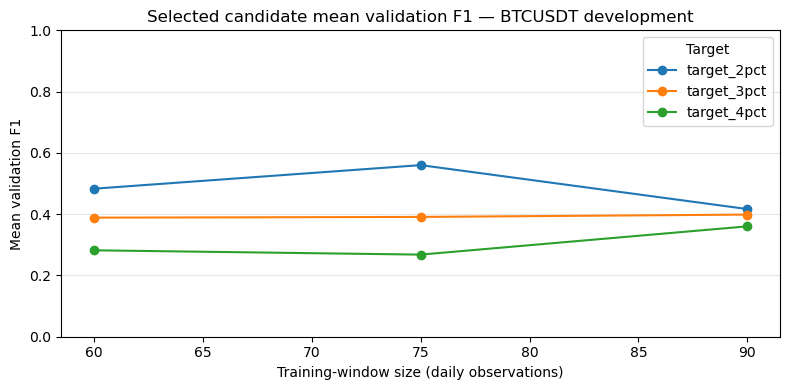

In [13]:
selected_columns = [
    'target',
    'window_size',
    'kernel',
    'C',
    'gamma',
    'degree',
    'coef0',
    'class_weight',
    'mean_accuracy',
    'mean_precision',
    'mean_recall',
    'mean_f1',
    'mean_roc_auc',
    'mean_average_precision',
]
selected = grid_result.selected_configurations.loc[:, selected_columns].copy()
display(selected)

plot_data = selected.pivot(index='window_size', columns='target', values='mean_f1')
ax = plot_data.plot(marker='o', figsize=(8, 4))
ax.set_title('Selected candidate mean validation F1 — BTCUSDT development')
ax.set_xlabel('Training-window size (daily observations)')
ax.set_ylabel('Mean validation F1')
ax.set_ylim(0, 1)
ax.grid(axis='y', alpha=0.3)
ax.legend(title='Target')
plt.tight_layout()
plt.show()

## 13. Persist reproducibility evidence

The writer stores eligibility, fold results, candidate rankings, selected configurations, a configuration snapshot, and run metadata with checksums. These generated artifacts remain outside Git.

In [14]:
artifact_paths = write_grid_search_outputs(
    grid_config, development_source, grid_result
)
artifact_table = pd.DataFrame(
    {
        'artifact': [path.name for path in artifact_paths],
        'path': [str(path) for path in artifact_paths],
        'exists': [path.exists() for path in artifact_paths],
    }
)
display(artifact_table)

,artifact,path,exists
0,asset_eligibility.csv,outputs/binance_daily_svm_temporal_grid_search...,True
1,fold_results.csv.gz,outputs/binance_daily_svm_temporal_grid_search...,True
2,candidate_results.csv.gz,outputs/binance_daily_svm_temporal_grid_search...,True
3,selected_configurations.csv,outputs/binance_daily_svm_temporal_grid_search...,True
4,configuration_snapshot.json,outputs/binance_daily_svm_temporal_grid_search...,True
5,run_metadata.json,outputs/binance_daily_svm_temporal_grid_search...,True


## 14. How to run other scopes

The notebook intentionally executes only the approved BTCUSDT operational validation. The command-line runner provides explicit expansion controls:

```bash
# BTCUSDT complete development grid search (default)
python scripts/run_daily_svm_grid_search.py

# Eligibility only for all 40 configured symbols
python scripts/run_daily_svm_grid_search.py --all-symbols --eligibility-only

# Complete development grid for all eligible symbol-target-window combinations
python scripts/run_daily_svm_grid_search.py --all-symbols
```

The final command is intentionally separate because it is substantially larger than the BTCUSDT validation. It still operates only on development data.

## Interpretation limits and next step

This notebook demonstrates model selection inside the development period. Its mean fold metrics compare hyperparameter candidates; they are not the definitive estimate of future performance. The reserved 2025-01-01 through 2026-08-31 feature period has not been evaluated here.

The next implementation stage is the frozen-parameter one-step walk-forward evaluator, including the constant-zero dummy, prior dummy, and default-SVC baselines. That stage must use the selected development parameters without revising the grid after final-test outcomes are observed.